# Channel selection — spike-count histogram and threshold exploration

The XGB overfitting check (train R² climbing to ~1.0 while test R² sits flat
around 0.15, see `analyze_param_search.ipynb`) points at a feature/sample
mismatch: ~4600 lagged features (355 channels x lag window) from ~10.6k
training samples. One direct lever is dropping channels that barely spike at
all -- this notebook computes the exact per-channel spike count
`theo_pipeline_new.py` sees (same time-window trim, same drift correction),
histograms it, and previews what different count thresholds would keep.

Needs the `decoding` conda env (spikeinterface + `theo_pipeline_new`'s own
imports) -- reads the recording + peaks + motion, so re-running takes ~1-2
minutes (dominated by `snap_to_nearest_channel`), not instant like the
params-search notebook.

## Setup — load the recording + peaks exactly as theo_pipeline_new.py does

In [1]:
import sys
sys.path.insert(0, "/raven/u/gongt/scripts/theo_decoding")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import spikeinterface.full as si
import theo_pipeline_new as tpn  # reuses get_corrected_positions / snap_to_nearest_channel /
                                   # to_seconds so channel assignment matches the real search exactly

# Same defaults as build_search_grid.py's FIXED_ARGS
RECORDING_PATH = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed"
PEAKS_PATH = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks_3.5/peaks_combined2_sorted.npy"
MOTION_PATH = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks_3.5/motion_estimates/motion_dredge"
LOCALIZED_PEAKS_PATH = "/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks_3.5/localized_peaks_mt_raw.npy"
BEHAVIOR_DF_PATH = "/ptmp/gongt/behaviour/texture_pca_df_preproc.pkl"
ANIMAL = "GLC6962"
BACKGROUND = "eink"

OUT_DIR = Path("/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/theo_pipeline_params_search/channel_selection")
OUT_DIR.mkdir(exist_ok=True)

rec = si.load(RECORDING_PATH)
peaks = np.load(PEAKS_PATH, allow_pickle=True)
channel_ids = rec.get_channel_ids()
channel_positions = rec.get_channel_locations()
fs = float(rec.get_sampling_frequency())
time_offset = float(rec.get_times()[0])
n_channels = channel_ids.shape[0]
print(f"{n_channels} channels, fs={fs:.1f}Hz")

peak_channel_index = peaks["channel_index"].astype(int)
peak_times_sec = peaks["sample_index"].astype(float) / fs + time_offset
if peak_channel_index.min() >= 0 and peak_channel_index.max() < n_channels:
    peak_row_index = peak_channel_index
else:
    ap_numbers = np.array([int(str(cid).split("AP")[-1]) for cid in channel_ids], dtype=int)
    ap_to_row = {ap: i for i, ap in enumerate(ap_numbers)}
    peak_row_index = np.array([ap_to_row[ch] for ch in peak_channel_index], dtype=int)
print(f"{len(peaks):,} total peaks")

355 channels, fs=30000.3Hz
1,895,659 total peaks


## Trim to the neural/behavior overlap window (same as the search)

In [2]:
texture_pca_df = pd.read_pickle(BEHAVIOR_DF_PATH)
beh = texture_pca_df[
    (texture_pca_df["animal"] == ANIMAL) & (texture_pca_df["background"].astype(str).str.lower() == BACKGROUND.lower())
].copy()
beh_t = tpn.to_seconds(beh["time"])

t_start = max(float(np.min(peak_times_sec)), float(np.min(beh_t)))
t_end = min(float(np.max(peak_times_sec)), float(np.max(beh_t)))
duration_s = t_end - t_start
print(f"Overlap window: {t_start:.2f}s - {t_end:.2f}s ({duration_s:.1f}s = {duration_s/60:.1f} min)")

peak_keep = (peak_times_sec >= t_start) & (peak_times_sec < t_end)
peak_times_trim = peak_times_sec[peak_keep]
peak_rows_trim_raw = peak_row_index[peak_keep]
print(f"{len(peak_times_trim):,} / {len(peaks):,} peaks fall inside the overlap window.")

Overlap window: 7.41s - 2658.65s (2651.2s = 44.2 min)
1,875,833 / 1,895,659 peaks fall inside the overlap window.


## Drift correction (same as the search, when the motion/localized-peaks files are present)

In [3]:
motion_path, localized_peaks_path = Path(MOTION_PATH), Path(LOCALIZED_PEAKS_PATH)
if motion_path.exists() and localized_peaks_path.exists():
    motion = si.Motion.load(str(motion_path))
    localized_peaks = np.load(str(localized_peaks_path), allow_pickle=True)
    localized_y_trim = localized_peaks["y"].astype(float)[peak_keep]
    raw_positions_trim = np.column_stack([channel_positions[peak_rows_trim_raw, 0], localized_y_trim])
    corrected_positions_trim = tpn.get_corrected_positions(peak_times_trim, raw_positions_trim, motion)
    peak_rows_trim = tpn.snap_to_nearest_channel(corrected_positions_trim, channel_positions)
    n_reassigned = int(np.sum(peak_rows_trim != peak_rows_trim_raw))
    print(f"Drift correction: {n_reassigned:,}/{len(peak_rows_trim):,} peaks reassigned to a different channel.")
else:
    peak_rows_trim = peak_rows_trim_raw
    print("Motion/localized-peaks files not found -- skipping drift correction (matches --skip-drift-correction).")

channel_spike_counts = np.bincount(peak_rows_trim, minlength=n_channels)
active_channel_idx = np.flatnonzero(channel_spike_counts > 0)
dropped_channel_idx = np.flatnonzero(channel_spike_counts == 0)
print(f"\n{active_channel_idx.size}/{n_channels} channels have >=1 spike in this window "
      f"({dropped_channel_idx.size} completely silent).")
print(f"Spike count -- min={channel_spike_counts.min()}, median={np.median(channel_spike_counts):.0f}, "
      f"max={channel_spike_counts.max()}")

channel_rate_hz = channel_spike_counts / duration_s
counts_df = pd.DataFrame({
    "channel_row": np.arange(n_channels),
    "channel_id": [str(c) for c in channel_ids],
    "depth_um": channel_positions[:, 1],
    "spike_count": channel_spike_counts,
    "firing_rate_hz": channel_rate_hz,
}).sort_values("channel_row")
counts_df.to_csv(OUT_DIR / "channel_spike_counts.csv", index=False)
print(f"\nSaved per-channel counts -> {OUT_DIR / 'channel_spike_counts.csv'}")

Drift correction: 1,287,118/1,875,833 peaks reassigned to a different channel.

355/355 channels have >=1 spike in this window (0 completely silent).
Spike count -- min=8, median=1851, max=90568

Saved per-channel counts -> /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/theo_pipeline_params_search/channel_selection/channel_spike_counts.csv


### Sanity check against a real search run

`run_params.json`'s `channels` block records exactly this computation for
every completed run -- cross-checking against one confirms this notebook's
channel definition matches the actual search, not just a plausible
approximation.

In [4]:
example_run = next(Path("/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/theo_pipeline_params_search/results").glob("*XGB_d1_n100_lr0.01*"), None)
if example_run:
    recorded = json.loads((example_run / "run_params.json").read_text())["resolved"]["channels"]
    print(f"Recorded in {example_run.name}/run_params.json: total={recorded['total']}, active={recorded['active']}, "
          f"dropped={len(recorded['dropped_zero_spikes'])}")
    print(f"Computed here:                                  total={n_channels}, active={active_channel_idx.size}, "
          f"dropped={dropped_channel_idx.size}")
    assert recorded["active"] == active_channel_idx.size, "Mismatch -- channel definition has diverged from the pipeline!"
    print("Match confirmed.")
else:
    print("No example run found to cross-check against (not fatal, just skips the sanity check).")

Recorded in 20260804_171639_XGB_d1_n100_lr0.01/run_params.json: total=355, active=355, dropped=0
Computed here:                                  total=355, active=355, dropped=0
Match confirmed.


## Histogram of per-channel spike counts

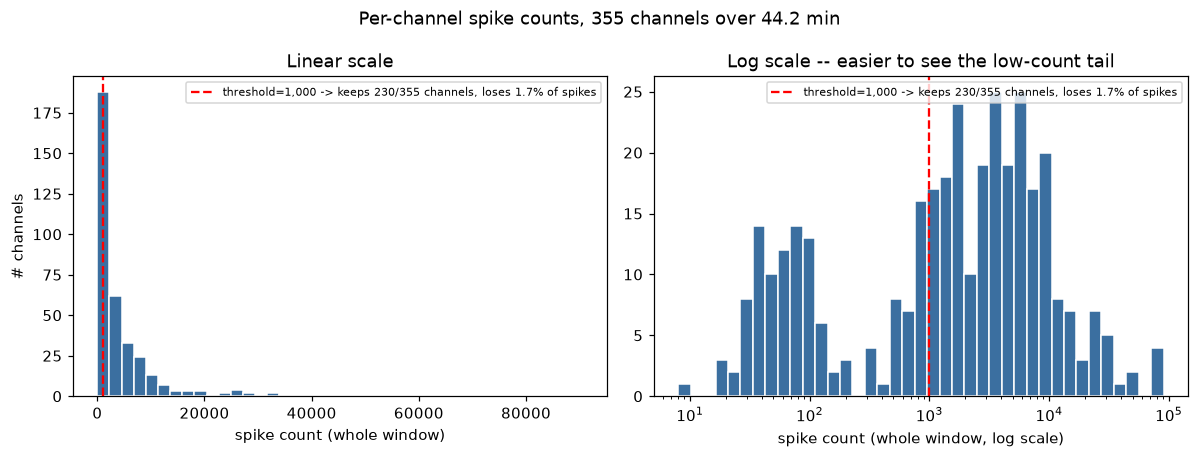

In [5]:
# Edit and re-run to try different cutoffs -- draws a red line on both
# panels below plus how many channels/spikes it would keep, so a threshold
# choice can be checked directly against the histogram shape. None = no line.
SPIKE_COUNT_THRESHOLD = 1000

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(channel_spike_counts, bins=40, color="#3B6FA0", edgecolor="white")
axes[0].set_xlabel("spike count (whole window)")
axes[0].set_ylabel("# channels")
axes[0].set_title("Linear scale")

axes[1].hist(channel_spike_counts, bins=np.logspace(np.log10(max(channel_spike_counts.min(), 1)),
             np.log10(channel_spike_counts.max()), 40), color="#3B6FA0", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_xlabel("spike count (whole window, log scale)")
axes[1].set_title("Log scale -- easier to see the low-count tail")

if SPIKE_COUNT_THRESHOLD is not None:
    n_kept = int((channel_spike_counts >= SPIKE_COUNT_THRESHOLD).sum())
    pct_lost = 100 * channel_spike_counts[channel_spike_counts < SPIKE_COUNT_THRESHOLD].sum() / channel_spike_counts.sum()
    label = f"threshold={SPIKE_COUNT_THRESHOLD:,} -> keeps {n_kept}/{n_channels} channels, loses {pct_lost:.1f}% of spikes"
    for ax in axes:
        ax.axvline(SPIKE_COUNT_THRESHOLD, color="red", linestyle="--", linewidth=1.5, label=label)
        ax.legend(fontsize=7.5, loc="upper right")

fig.suptitle(f"Per-channel spike counts, {n_channels} channels over {duration_s/60:.1f} min")
fig.tight_layout()
fig.savefig(OUT_DIR / "channel_spike_count_histogram.png", dpi=150)
plt.show()

## Threshold exploration

For a sweep of candidate minimum-spike-count thresholds: how many channels
would survive, and what fraction of all recorded spikes do the *dropped*
channels account for (i.e. how much are you actually giving up, not just how
many channels).

 min_spike_count_threshold  n_channels_kept  pct_spikes_lost
                         0              355         0.000000
                         1              355         0.000000
                         2              355         0.000000
                         3              355         0.000000
                         4              355         0.000000
                         7              355         0.000000
                        10              354         0.000426
                        15              354         0.000426
                        21              351         0.003518
                        23              351         0.003518
                        34              341         0.018339
                        37              338         0.023989
                        51              320         0.064825
                        75              297         0.142657
                       112              278         0.236961
                       1

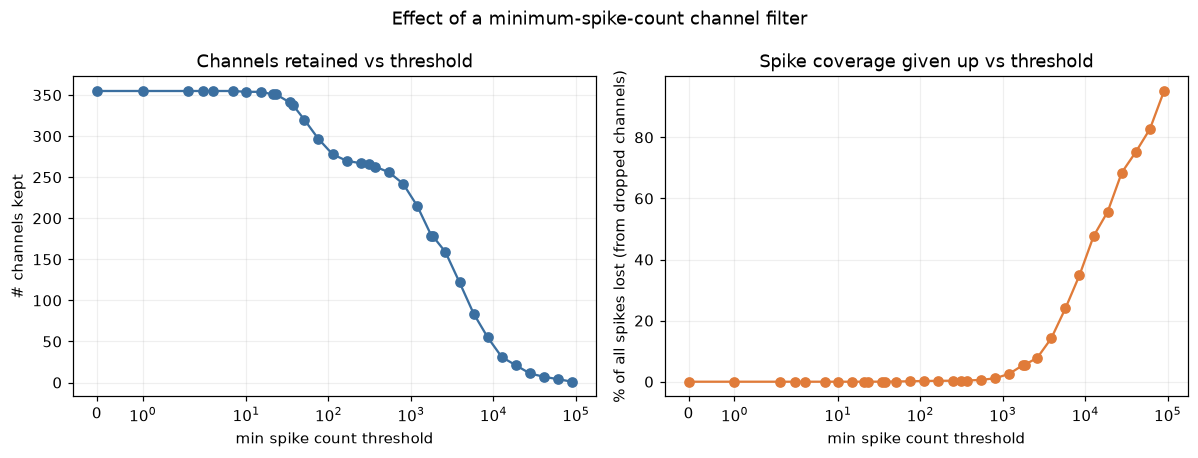

In [6]:
thresholds = np.unique(np.concatenate([
    [0], np.percentile(channel_spike_counts, [1, 5, 10, 25, 50]).astype(int),
    np.geomspace(1, channel_spike_counts.max(), 30).astype(int),
]))
total_spikes = channel_spike_counts.sum()
sweep = pd.DataFrame({
    "min_spike_count_threshold": thresholds,
    "n_channels_kept": [(channel_spike_counts >= t).sum() for t in thresholds],
    "pct_spikes_lost": [100 * channel_spike_counts[channel_spike_counts < t].sum() / total_spikes for t in thresholds],
})
sweep.to_csv(OUT_DIR / "threshold_sweep.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(sweep.min_spike_count_threshold, sweep.n_channels_kept, "o-", color="#3B6FA0")
axes[0].set_xscale("symlog")
axes[0].set_xlabel("min spike count threshold")
axes[0].set_ylabel("# channels kept")
axes[0].set_title("Channels retained vs threshold")
axes[0].grid(alpha=0.2)

axes[1].plot(sweep.min_spike_count_threshold, sweep.pct_spikes_lost, "o-", color="#E07B39")
axes[1].set_xscale("symlog")
axes[1].set_xlabel("min spike count threshold")
axes[1].set_ylabel("% of all spikes lost (from dropped channels)")
axes[1].set_title("Spike coverage given up vs threshold")
axes[1].grid(alpha=0.2)

fig.suptitle("Effect of a minimum-spike-count channel filter")
fig.tight_layout()
fig.savefig(OUT_DIR / "threshold_sweep.png", dpi=150)
plt.show()

print(sweep.to_string(index=False))

## Next steps

- Pick a threshold from the sweep above (e.g. one that drops the dead tail
  while losing <1-2% of total spikes) and decide the channel list:
  `active_channel_idx[channel_spike_counts[active_channel_idx] >= THRESHOLD]`.
- `theo_pipeline_new.py` has no `--min-channel-spikes` / explicit channel-list
  flag yet -- wiring the chosen threshold (or channel list) in as a new CLI
  option is a small, separate change once a threshold is picked here.
- Worth comparing against `--channel-smooth-window` (grouping instead of
  dropping) rather than treating them as either/or.